# Lab 5: Clustering Techniques Using DBSCAN and Hierarchical Clustering

**Student Name:** Nikhil  
**Course Title:** MSCS 634  
**Lab Assignment:** Lab 5 - Clustering Techniques Using DBSCAN and Hierarchical Clustering

## Step 1 - Data Preparation and Exploration

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Load the Wine dataset
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target  # Used only for evaluation, not for clustering

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Wine classes available for evaluation:", list(wine.target_names))

display(X.head())

Dataset shape: (178, 13)
Number of features: 13
Wine classes available for evaluation: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [ ]:
print("Dataset information:")
X.info()

print("\\nDescriptive statistics:")
display(X.describe().T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null 

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [ ]:
# Standardize all features so each feature contributes on a comparable scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized data shape:", X_scaled.shape)
print("Approximate standardized feature means (first 5):",
      np.round(X_scaled.mean(axis=0)[:5], 3))
print("Approximate standardized feature standard deviations (first 5):",
      np.round(X_scaled.std(axis=0)[:5], 3))

Standardized data shape: (178, 13)
Approximate standardized feature means (first 5): [ 0.  0. -0. -0. -0.]
Approximate standardized feature standard deviations (first 5): [1. 1. 1. 1. 1.]


## Visualization approach

The dataset contains 13 features, so the plots below use **alcohol** and **color intensity** as two interpretable dimensions for a simple 2D view. The clustering algorithms still use **all 13 standardized features**. Therefore, a 2D plot is a visual projection of the results rather than the full clustering space.

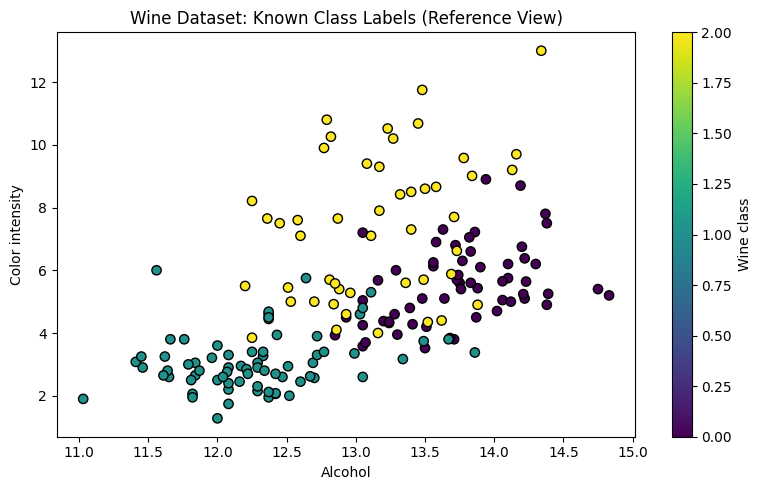

In [ ]:
plot_x = X["alcohol"].to_numpy()
plot_y = X["color_intensity"].to_numpy()

plt.figure(figsize=(8, 5))
plt.scatter(plot_x, plot_y, c=y_true, cmap="viridis", edgecolor="black", s=45)
plt.xlabel("Alcohol")
plt.ylabel("Color intensity")
plt.title("Wine Dataset: Known Class Labels (Reference View)")
plt.colorbar(label="Wine class")
plt.tight_layout()
plt.show()

## Step 2 - Agglomerative Hierarchical Clustering

In [ ]:
hierarchical_results = {}

for k in [2, 3, 4, 5]:
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_scaled)
    hierarchical_results[k] = labels
    print(f"n_clusters={k}: cluster sizes = {dict(zip(*np.unique(labels, return_counts=True)))}")

n_clusters=2: cluster sizes = {np.int64(0): np.int64(122), np.int64(1): np.int64(56)}
n_clusters=3: cluster sizes = {np.int64(0): np.int64(58), np.int64(1): np.int64(56), np.int64(2): np.int64(64)}
n_clusters=4: cluster sizes = {np.int64(0): np.int64(56), np.int64(1): np.int64(30), np.int64(2): np.int64(64), np.int64(3): np.int64(28)}
n_clusters=5: cluster sizes = {np.int64(0): np.int64(64), np.int64(1): np.int64(30), np.int64(2): np.int64(36), np.int64(3): np.int64(28), np.int64(4): np.int64(20)}


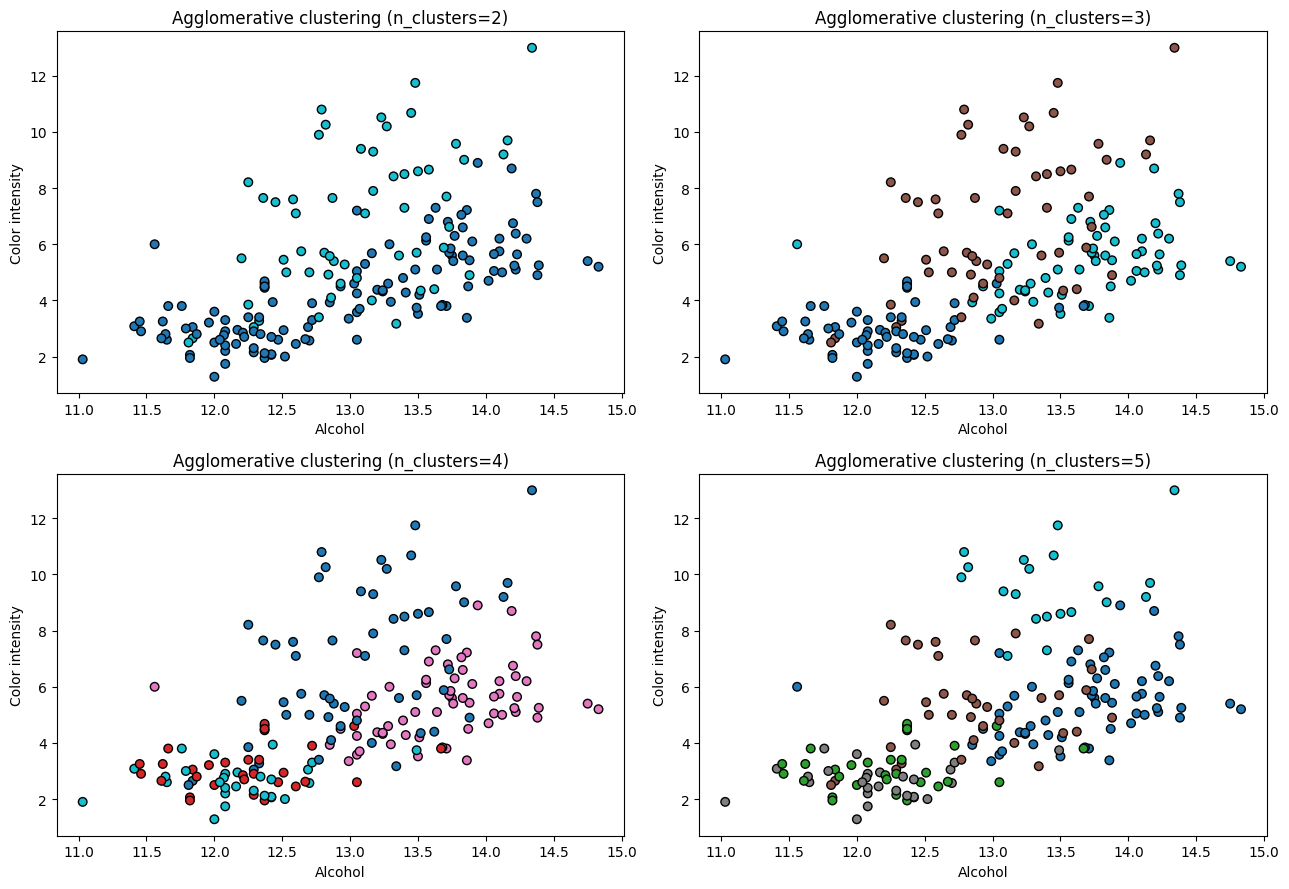

In [ ]:
# Plot the hierarchical cluster assignments for each tested cluster count
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, k in zip(axes.ravel(), [2, 3, 4, 5]):
    labels = hierarchical_results[k]
    scatter = ax.scatter(plot_x, plot_y, c=labels, cmap="tab10",
                         edgecolor="black", s=38)
    ax.set_title(f"Agglomerative clustering (n_clusters={k})")
    ax.set_xlabel("Alcohol")
    ax.set_ylabel("Color intensity")
plt.tight_layout()
plt.show()

### Dendrogram

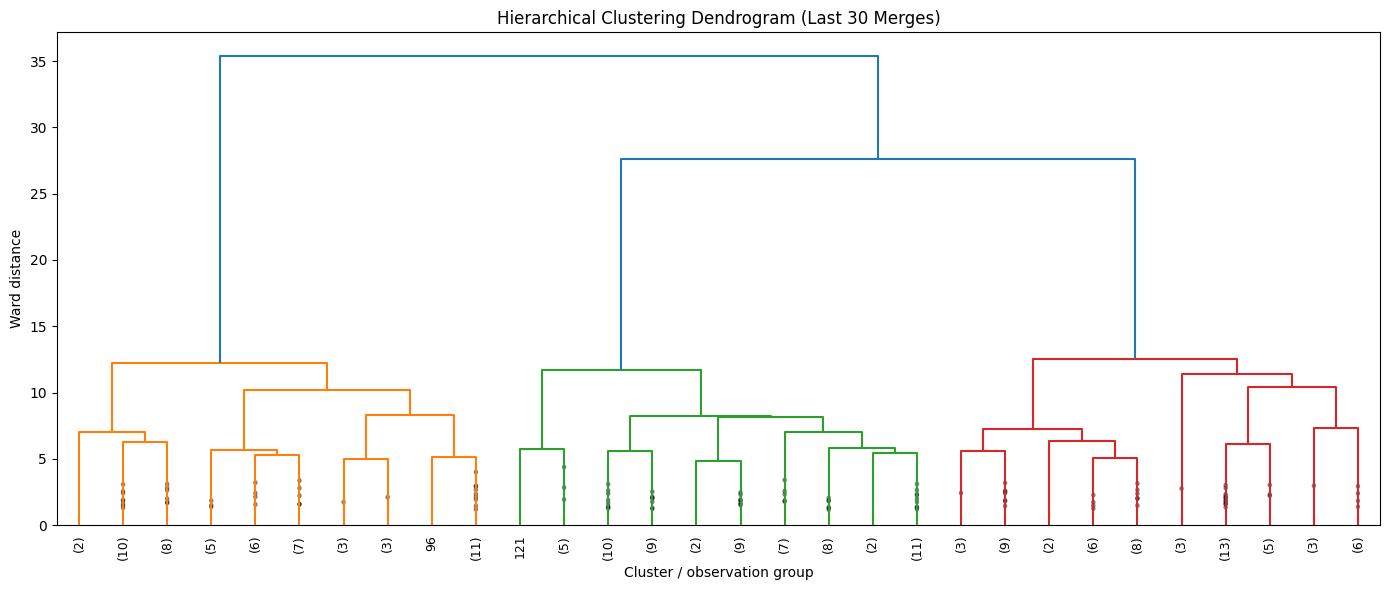

In [ ]:
# Ward linkage on the standardized feature matrix
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90,
           leaf_font_size=9, show_contracted=True)
plt.title("Hierarchical Clustering Dendrogram (Last 30 Merges)")
plt.xlabel("Cluster / observation group")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

## Step 3 - DBSCAN Clustering

In [ ]:
# Test multiple eps and min_samples settings
dbscan_settings = [
    (0.8, 5),
    (1.2, 5),
    (1.5, 5),
    (2.0, 5),
    (1.2, 10),
    (1.5, 10),
]

dbscan_results = []
for eps, min_samples in dbscan_settings:
    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int(np.sum(labels == -1))
    dbscan_results.append({
        "eps": eps,
        "min_samples": min_samples,
        "n_clusters_excluding_noise": n_clusters,
        "noise_points": n_noise,
        "labels": labels
    })
    print(f"eps={eps}, min_samples={min_samples} -> "
          f"clusters={n_clusters}, noise points={n_noise}")

eps=0.8, min_samples=5 -> clusters=0, noise points=178
eps=1.2, min_samples=5 -> clusters=0, noise points=178
eps=1.5, min_samples=5 -> clusters=0, noise points=178
eps=2.0, min_samples=5 -> clusters=5, noise points=85
eps=1.2, min_samples=10 -> clusters=0, noise points=178
eps=1.5, min_samples=10 -> clusters=0, noise points=178


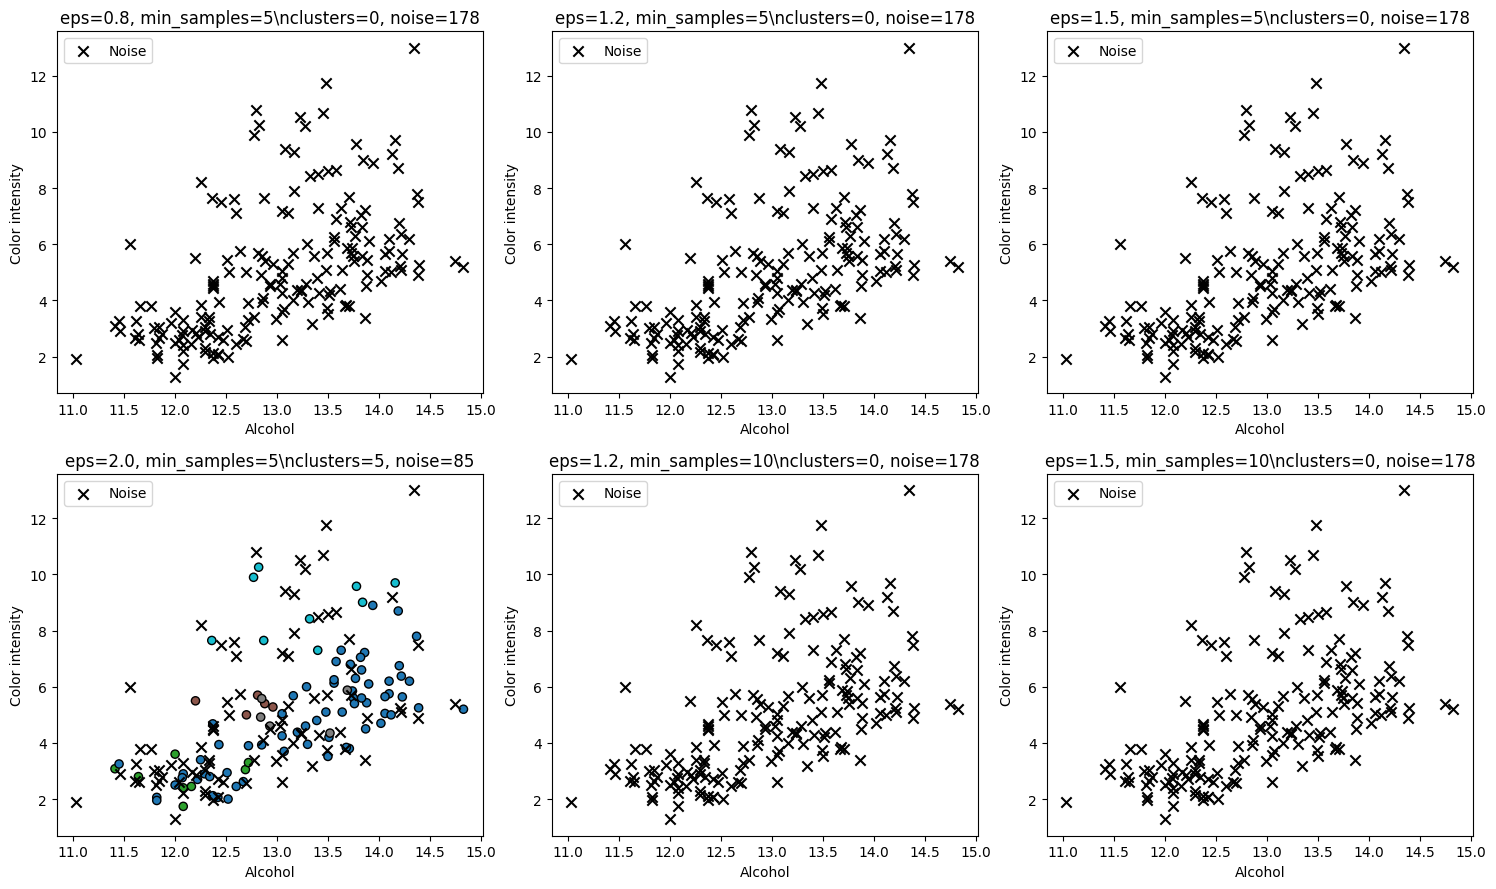

In [ ]:
# Visualize DBSCAN assignments. Noise points (label -1) are highlighted in black.
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, result in zip(axes.ravel(), dbscan_results):
    labels = result["labels"]
    noise = labels == -1
    non_noise = ~noise

    if np.any(non_noise):
        ax.scatter(plot_x[non_noise], plot_y[non_noise],
                   c=labels[non_noise], cmap="tab10", edgecolor="black", s=35)
    if np.any(noise):
        ax.scatter(plot_x[noise], plot_y[noise], c="black", marker="x",
                   s=55, label="Noise")
        ax.legend()
    ax.set_title(f"eps={result['eps']}, min_samples={result['min_samples']}\\n"
                 f"clusters={result['n_clusters_excluding_noise']}, "
                 f"noise={result['noise_points']}")
    ax.set_xlabel("Alcohol")
    ax.set_ylabel("Color intensity")
plt.tight_layout()
plt.show()

### DBSCAN evaluation metrics

In [ ]:
metric_rows = []

for result in dbscan_results:
    labels = result["labels"]
    non_noise = labels != -1
    labels_non_noise = labels[non_noise]
    y_non_noise = y_true[non_noise]
    n_clusters = result["n_clusters_excluding_noise"]

    # External metrics can be computed for assigned (non-noise) observations.
    if np.sum(non_noise) > 0:
        homogeneity = homogeneity_score(y_non_noise, labels_non_noise)
        completeness = completeness_score(y_non_noise, labels_non_noise)
    else:
        homogeneity = np.nan
        completeness = np.nan

    # Silhouette requires at least 2 clusters and fewer clusters than samples.
    if n_clusters >= 2 and np.unique(labels_non_noise).size >= 2 and len(labels_non_noise) > n_clusters:
        silhouette = silhouette_score(X_scaled[non_noise], labels_non_noise)
    else:
        silhouette = np.nan

    metric_rows.append({
        "eps": result["eps"],
        "min_samples": result["min_samples"],
        "clusters (excluding noise)": n_clusters,
        "noise points": int(np.sum(~non_noise)),
        "silhouette score": silhouette,
        "homogeneity score": homogeneity,
        "completeness score": completeness
    })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(4))

,eps,min_samples,clusters (excluding noise),noise points,silhouette score,homogeneity score,completeness score
0,0.8,5,0,178,NaN,NaN,NaN
1,1.2,5,0,178,NaN,NaN,NaN
2,1.5,5,0,178,NaN,NaN,NaN
3,2.0,5,5,85,0.2405,0.5858,0.6056
4,1.2,10,0,178,NaN,NaN,NaN
5,1.5,10,0,178,NaN,NaN,NaN


### Selecting and inspecting a DBSCAN result

In [ ]:
valid_metrics = metrics_df.dropna(subset=["silhouette score"])

if not valid_metrics.empty:
    best_row = valid_metrics.loc[valid_metrics["silhouette score"].idxmax()]
    selection_reason = "highest valid silhouette score among the tested settings"
else:
    best_row = metrics_df.loc[metrics_df["noise points"].idxmin()]
    selection_reason = "fewest noise points because no tested setting had a valid silhouette score"

best_eps = float(best_row["eps"])
best_min_samples = int(best_row["min_samples"])
best_model = DBSCAN(eps=best_eps, min_samples=best_min_samples)
best_labels = best_model.fit_predict(X_scaled)

print(f"Selected eps={best_eps}, min_samples={best_min_samples}")
print("Selection rule:", selection_reason)
print("Cluster labels (including -1 for noise):", np.unique(best_labels))
print("Cluster sizes:", dict(zip(*np.unique(best_labels, return_counts=True))))

Selected eps=2.0, min_samples=5
Selection rule: highest valid silhouette score among the tested settings
Cluster labels (including -1 for noise): [-1  0  1  2  3  4]
Cluster sizes: {np.int64(-1): np.int64(85), np.int64(0): np.int64(66), np.int64(1): np.int64(8), np.int64(2): np.int64(5), np.int64(3): np.int64(5), np.int64(4): np.int64(9)}


## Step 4 - Analysis and Insights

In [ ]:
# Summarize hierarchical cluster sizes
hierarchical_summary = []
for k, labels in hierarchical_results.items():
    counts = pd.Series(labels).value_counts().sort_index().to_dict()
    score = silhouette_score(X_scaled, labels) if len(np.unique(labels)) > 1 else np.nan
    hierarchical_summary.append({
        "n_clusters": k,
        "cluster_sizes": counts,
        "silhouette score": score
    })

hierarchical_summary_df = pd.DataFrame(hierarchical_summary)
display(hierarchical_summary_df.round(4))

print("DBSCAN parameter comparison:")
display(metrics_df.round(4))

,n_clusters,cluster_sizes,silhouette score
0,2,"{0: 122, 1: 56}",0.2670
1,3,"{0: 58, 1: 56, 2: 64}",0.2774
2,4,"{0: 56, 1: 30, 2: 64, 3: 28}",0.2258
3,5,"{0: 64, 1: 30, 2: 36, 3: 28, 4: 20}",0.1867


DBSCAN parameter comparison:


,eps,min_samples,clusters (excluding noise),noise points,silhouette score,homogeneity score,completeness score
0,0.8,5,0,178,NaN,NaN,NaN
1,1.2,5,0,178,NaN,NaN,NaN
2,1.5,5,0,178,NaN,NaN,NaN
3,2.0,5,5,85,0.2405,0.5858,0.6056
4,1.2,10,0,178,NaN,NaN,NaN
5,1.5,10,0,178,NaN,NaN,NaN


### Written interpretation

**Hierarchical clustering:** Agglomerative clustering always produces the requested number of clusters in these experiments. This makes it useful when a specific cluster count is required, and the dendrogram helps show how groups merge. However, it is sensitive to the chosen linkage and cluster count, and once observations have been merged, the algorithm does not undo those merges.

**DBSCAN:** DBSCAN does not require the number of clusters to be specified in advance and can identify observations as noise. This is useful when groups are dense and separated. However, the result can change substantially with `eps` and `min_samples`; one setting may merge many observations into a large cluster, while another may classify many observations as noise. DBSCAN can also struggle when clusters have different densities.

**Comparison:** Hierarchical clustering is more predictable when the desired number of groups is known, while DBSCAN is valuable for detecting dense regions and potential outliers. Compare the cluster plots, dendrogram, cluster sizes, and DBSCAN metrics before deciding which result is more useful for this Wine dataset. A high silhouette score alone is not enough: the amount of noise and the homogeneity/completeness scores also matter.

**Limitations:** The scatter plots display only alcohol and color intensity, while clustering used all 13 standardized features. Consequently, points that overlap in a 2D plot may still differ across other features. The conclusions are specific to this dataset and the parameter values tested.

## Conclusion

This lab explored the Wine dataset with standardized features, Agglomerative Hierarchical Clustering, and DBSCAN. Hierarchical clustering was compared across four requested cluster counts and visualized with a dendrogram. DBSCAN was tested with several `eps` and `min_samples` combinations, with noise points highlighted and silhouette, homogeneity, and completeness scores reported where applicable. The most appropriate method depends on the observed cluster structure, the amount of noise, and the purpose of the analysis.